# Chapter 3 · The common distributions

*Book 3 · Probability · Shelf I*

**Builds on:** [Chapter 2](02-random-variables.ipynb) -- pmf, pdf, cdf, expectation.
**You will:** meet the distributions that keep coming back and the processes that produce them, fit
four of them to the same data, choose between them with Q-Q plots and AIC -- and find that the
choice barely matters for the data and enormously for the tail.

A handful of distributions cover most of practice, because they come from simple mechanisms:
**binomial** -- count successes in $n$ tries; **Poisson** -- count rare events in a period;
**exponential** -- the wait between such events; **normal** -- the sum of many small effects;
**lognormal** -- the product of many small effects; **gamma** and **Weibull** -- flexible positive
quantities, waits and lifetimes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ds_toolbox import io, viz

viz.use_style()
rng = np.random.default_rng(3)

## Mechanisms make distributions

Sums of many small independent effects become normal; products become lognormal (the log of a
product is a sum). Simulated, not assumed:

skewness, sum -0.00 · product +1.44


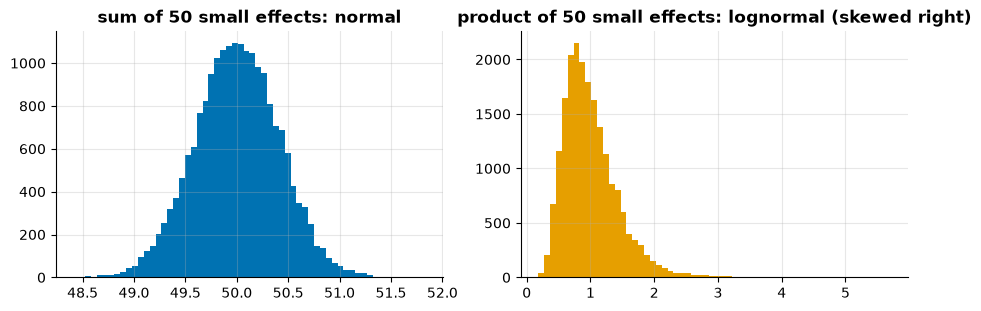

In [2]:
effects = rng.uniform(0.9, 1.1, size=(20000, 50))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(effects.sum(axis=1), bins=60, color=viz.PALETTE[0])
axes[0].set_title("sum of 50 small effects: normal")
axes[1].hist(effects.prod(axis=1), bins=60, color=viz.PALETTE[1])
axes[1].set_title("product of 50 small effects: lognormal (skewed right)")
print(f"skewness, sum {stats.skew(effects.sum(axis=1)):+.2f} · product {stats.skew(effects.prod(axis=1)):+.2f}")

## Rare events: Poisson and exponential

If rocks fall independently at a constant rate, the count per week is Poisson and the time between
two rocks is exponential -- two views of one process. The seeded season, zone 1:

In [3]:
season = io.load_sample("rockfall_season.csv", parse_dates=["time"])
z1 = season[season.zone == "zone 1"].sort_values("time")
gaps_h = z1.time.diff().dropna().dt.total_seconds() / 3600
rate = 1 / gaps_h.mean()
per_week = z1.set_index("time").resample("7D").size()
print(f"{len(z1)} rocks · mean gap {gaps_h.mean():.1f} h · per week: mean {per_week.mean():.2f}, "
      f"variance {per_week.var():.2f} (Poisson: equal)")

61 rocks · mean gap 35.8 h · per week: mean 4.69, variance 4.23 (Poisson: equal)


## Four families, one dataset

Fit lognormal, gamma, Weibull and exponential to zone 1's rock masses by maximum likelihood and
compare them three ways: a Q-Q plot (do the quantiles line up?), **AIC** (fit penalised by the
number of parameters; lower is better), and what each says about a very large rock.

In [4]:
mass = z1.mass.to_numpy()
families = {"lognormal": stats.lognorm, "gamma": stats.gamma, "weibull": stats.weibull_min,
            "exponential": stats.expon}
fits, rows = {}, []
for name, dist in families.items():
    params = dist.fit(mass, floc=0)
    fits[name] = dist(*params)
    k = len(params) - 1                                    # the location is fixed, not fitted
    aic = 2 * k - 2 * fits[name].logpdf(mass).sum()
    rows.append({"family": name, "AIC": aic, "median, kg": fits[name].median(),
                 "P(mass > 5 t)": fits[name].sf(5_000), "P(mass > 20 t)": fits[name].sf(20_000)})
table = pd.DataFrame(rows).set_index("family").sort_values("AIC")
table.style.format({"AIC": "{:.1f}", "median, kg": "{:.0f}",
                    "P(mass > 5 t)": "{:.1e}", "P(mass > 20 t)": "{:.1e}"})

,AIC,"median, kg",P(mass > 5 t),P(mass > 20 t)
family,,,,
exponential,911.4,440,3.8e-04,2.1e-14
weibull,911.6,484,4.2e-05,3.5e-22
gamma,911.6,476,1.1e-04,2.3e-17
lognormal,926.1,404,1.4e-02,3.3e-04


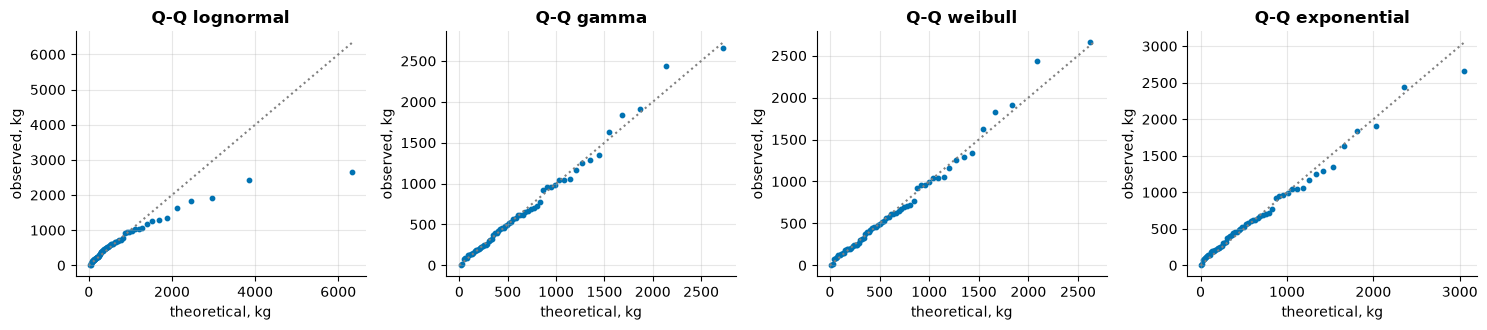

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
probs = (np.arange(1, len(mass) + 1) - 0.5) / len(mass)
for ax, (name, f) in zip(axes, fits.items(), strict=True):
    ax.scatter(f.ppf(probs), np.sort(mass), s=10)
    lim = max(mass.max(), f.ppf(probs[-1]))
    ax.plot([0, lim], [0, lim], color="0.5", ls=":")
    ax.set(title=f"Q-Q {name}", xlabel="theoretical, kg", ylabel="observed, kg")
fig.tight_layout()

On this season the three light-tailed families tie on AIC (within 0.2) and the lognormal is
clearly worse, about 15 points behind. All four put the median rock between 400 and 490 kg. For a
20-tonne rock -- far beyond anything observed -- they disagree by eighteen orders of magnitude.

Here AIC points the right way: the seeded world's true masses are gamma. But it does so on 61
rocks, and it compares fit where the data is, not where the risk is. On the 68 rocks the 2019
report printed, the lognormal won. Whether one season's ranking can be trusted is a question
about many seasons -- the challenge asks it.

## What to remember

- Distributions come from mechanisms: sums are normal, products lognormal, rare counts Poisson.
- Choose a family with Q-Q plots and AIC -- for the data you have.
- Neither tool can tell you about the tail beyond the data. Say so when the answer depends on it.

## Exercises

1. Fit the four families to zone 2's masses. Which wins on AIC, and do the tails disagree as much?
2. Simulate a Poisson process with rate 1 per hour and check that the gaps are exponential.
3. Refit with only the first 30 rocks. Does the AIC winner change?

**Next:** [Chapter 4 · Joint, conditional, Bayes](04-joint-conditional-bayes.ipynb)